<a href="https://colab.research.google.com/github/04231073/Smart_City_MultiZone_Load_Forecasting/blob/main/01_EDA_and_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# 1. Load dataset
df = pd.read_csv('Tetuan City power consumption.csv')

# 2. Bersihkan spasi berlebih pada nama kolom
df.columns = df.columns.str.strip()

# 3. Konversi kolom DateTime menjadi format datetime dan urutkan secara kronologis
df['DateTime'] = pd.to_datetime(df['DateTime'])
df = df.sort_values('DateTime').reset_index(drop=True)

print(f"Dimensi Dataset: {df.shape[0]} baris x {df.shape[1]} kolom")
print(f"Rentang Waktu  : {df['DateTime'].min()} s.d. {df['DateTime'].max()}")
display(df.head())

Dimensi Dataset: 52416 baris x 9 kolom
Rentang Waktu  : 2017-01-01 00:00:00 s.d. 2017-12-30 23:50:00


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [3]:
# 1. Cek Missing Values dan Tipe Data
df_quality = pd.DataFrame({
    "Tipe Data": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Persentase Missing (%)": (df.isnull().sum() / len(df)) * 100
})

print("=== LAPORAN KUALITAS DATASET & MISSING VALUES ===")
display(df_quality)

# 2. Cek Duplikasi Timestamp
jumlah_duplikat = df.duplicated(subset=['DateTime']).sum()
print(f"\nJumlah baris duplikat berdasarkan DateTime: {jumlah_duplikat}")

=== LAPORAN KUALITAS DATASET & MISSING VALUES ===


,Tipe Data,Missing Values,Persentase Missing (%)
DateTime,datetime64[ns],0,0.0
Temperature,float64,0,0.0
Humidity,float64,0,0.0
Wind Speed,float64,0,0.0
general diffuse flows,float64,0,0.0
diffuse flows,float64,0,0.0
Zone 1 Power Consumption,float64,0,0.0
Zone 2 Power Consumption,float64,0,0.0
Zone 3 Power Consumption,float64,0,0.0



Jumlah baris duplikat berdasarkan DateTime: 0


In [4]:
# Statistik ringkasan untuk seluruh variabel numerik
df_stats = df.describe().T[['mean', 'std', 'min', '50%', 'max']]
df_stats.columns = ['Rata-rata', 'Standar Deviasi', 'Minimum', 'Median (50%)', 'Maksimum']

print("=== STATISTIK DESKRIPTIF DATASET TETOUAN CITY ===")
display(df_stats.round(3))

=== STATISTIK DESKRIPTIF DATASET TETOUAN CITY ===


,Rata-rata,Standar Deviasi,Minimum,Median (50%),Maksimum
DateTime,2017-07-01 23:55:00,NaN,2017-01-01 00:00:00,2017-07-01 23:55:00,2017-12-30 23:50:00
Temperature,18.810024,5.815476,3.247,18.78,40.01
Humidity,68.259518,15.551177,11.34,69.86,94.8
Wind Speed,1.959489,2.348862,0.05,0.086,6.483
general diffuse flows,182.696614,264.40096,0.004,5.0355,1163.0
diffuse flows,75.028022,124.210949,0.011,4.456,936.0
Zone 1 Power Consumption,32344.970564,7130.562564,13895.6962,32265.92034,52204.39512
Zone 2 Power Consumption,21042.509082,5201.465892,8560.081466,20823.168405,37408.86076
Zone 3 Power Consumption,17835.406218,6622.165099,5935.17407,16415.11747,47598.32636


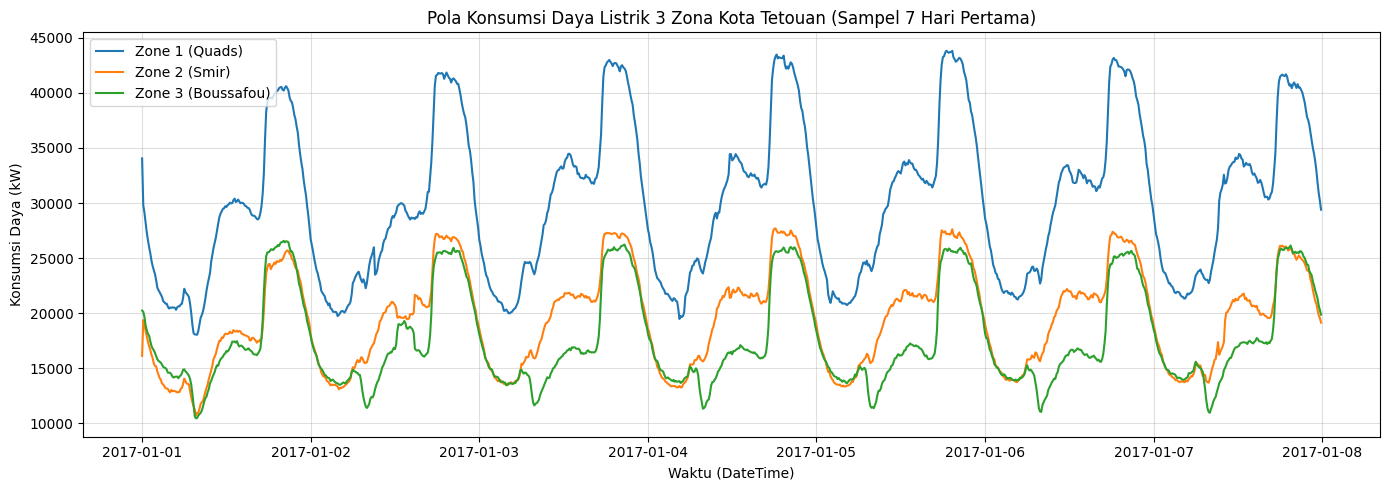

In [5]:
# Ambil sampel 1 minggu pertama (1.008 baris = 7 hari x 144 interval 10 menit) agar pola harian terlihat jelas
sample_week = df.iloc[:1008]

plt.figure(figsize=(14, 5))
plt.plot(sample_week['DateTime'], sample_week['Zone 1 Power Consumption'], label='Zone 1 (Quads)', color='tab:blue')
plt.plot(sample_week['DateTime'], sample_week['Zone 2  Power Consumption'], label='Zone 2 (Smir)', color='tab:orange')
plt.plot(sample_week['DateTime'], sample_week['Zone 3  Power Consumption'], label='Zone 3 (Boussafou)', color='tab:green')

plt.title('Pola Konsumsi Daya Listrik 3 Zona Kota Tetouan (Sampel 7 Hari Pertama)')
plt.xlabel('Waktu (DateTime)')
plt.ylabel('Konsumsi Daya (kW)')
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

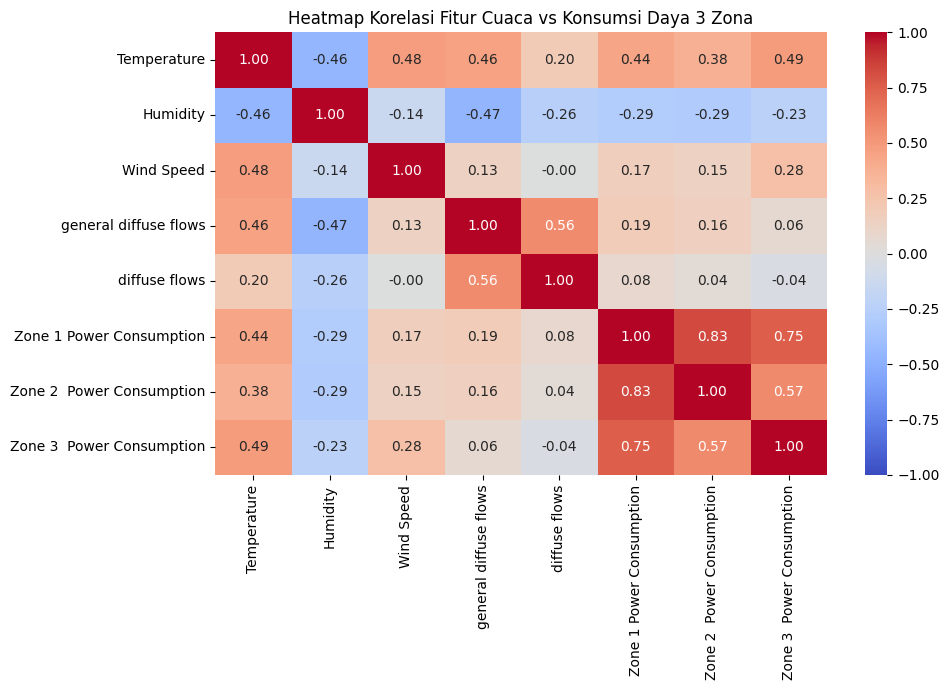

In [6]:
plt.figure(figsize=(10, 7))
corr_matrix = df.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Heatmap Korelasi Fitur Cuaca vs Konsumsi Daya 3 Zona')
plt.tight_layout()
plt.show()

In [7]:
# 1. Feature Engineering Temporal
df['Hour'] = df['DateTime'].dt.hour
df['Minute'] = df['DateTime'].dt.minute
time_in_hours = df['Hour'] + df['Minute'] / 60.0

df['Hour_sin'] = np.sin(2 * np.pi * time_in_hours / 24.0)
df['Hour_cos'] = np.cos(2 * np.pi * time_in_hours / 24.0)
df['DayOfWeek'] = df['DateTime'].dt.dayofweek
df['Month'] = df['DateTime'].dt.month

feature_cols = [
    'Temperature', 'Humidity', 'Wind Speed',
    'general diffuse flows', 'diffuse flows',
    'Hour_sin', 'Hour_cos', 'DayOfWeek', 'Month'
]
target_cols = [
    'Zone 1 Power Consumption',
    'Zone 2  Power Consumption',
    'Zone 3  Power Consumption'
]

# 2. Pembagian Dataset Kronologis (70% Train, 15% Validation, 15% Test) - Tanpa Shuffle!
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end]
val_df = df.iloc[train_end:val_end]
test_df = df.iloc[val_end:]

# 3. Normalisasi (Fit HANYA pada data Train untuk mencegah Data Leakage)
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(train_df[feature_cols])
y_train_scaled = scaler_y.fit_transform(train_df[target_cols])

X_val_scaled = scaler_X.transform(val_df[feature_cols])
y_val_scaled = scaler_y.transform(val_df[target_cols])

X_test_scaled = scaler_X.transform(test_df[feature_cols])
y_test_scaled = scaler_y.transform(test_df[target_cols])

print("=== RINGKASAN PEMBAGIAN DATA (ANTI DATA LEAKAGE) ===")
print(f"Train Set      : {X_train_scaled.shape[0]} baris ({train_df['DateTime'].min().date()} s.d. {train_df['DateTime'].max().date()})")
print(f"Validation Set : {X_val_scaled.shape[0]} baris ({val_df['DateTime'].min().date()} s.d. {val_df['DateTime'].max().date()})")
print(f"Test Set       : {X_test_scaled.shape[0]} baris ({test_df['DateTime'].min().date()} s.d. {test_df['DateTime'].max().date()})")

=== RINGKASAN PEMBAGIAN DATA (ANTI DATA LEAKAGE) ===
Train Set      : 36691 baris (2017-01-01 s.d. 2017-09-12)
Validation Set : 7862 baris (2017-09-12 s.d. 2017-11-06)
Test Set       : 7863 baris (2017-11-06 s.d. 2017-12-30)
